# Aberration demonstration: differentiate the ray components

Trace **one on-axis reference ray** through a component and differentiate the resulting ray transformation with `jax.experimental.jet`. Recover the aberration coefficients from its output position/slope derivatives:

- `KrivanekLensCartesian`: first- through fifth-order slope jets recover every implemented Krivanek amplitude and orientation.
- `SeidelLens`: the third-order position **and** slope jet recovers all nine Seidel coefficients.

Both examples call the actual components with `Ray` objects. No wave-aberration function or `phase_shift` is called by the extraction routines. The unknown coefficients live inside the forward components; their stored values are accessed only to construct the synthetic examples and score recovery.

A single reference ray means one **primal**, with position and slope zero. Several tangent seeds resolve its multivariate jet; these are derivatives at that same primal, not a set of off-axis rays used for fitting. Off-axis ray traces appear only in the final validation and plots.

In [1]:
from pathlib import Path
import sys
from math import factorial

repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/temgym_core").is_dir())
sys.path.insert(0, str(repo / "src"))

import jax
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")  # Small derivative problems; no GPU needed.
import jax.numpy as jnp
from jax.experimental.jet import jet
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from temgym_core.ray import Ray
from temgym_core.components import Lens, Plane, KrivanekLens, KrivanekLensCartesian, SeidelLens
from temgym_core.aberrations import KrivanekCoeffs, SeidelCoeffs
from temgym_core.run import run_to_end

reference_ray = Ray.origin()
reference_coordinates = jnp.zeros(4)  # (x, y, dx, dy)
print(f"JAX {jax.__version__}, float64={jax.config.x64_enabled}, {jax.devices()[0].platform}")
print("Reference ray:", reference_ray)

JAX 0.10.2, float64=True, cpu
Reference ray: Ray(x=0.0, y=0.0, dx=0.0, dy=0.0, z=0.0, pathlength=0.0, voltage=200000.0, _one=1.0)


## 1. Jet of a ray transformation

Wrap a component or column as $F:(x,y,p_x,p_y)_{\rm in}\mapsto(x,y,p_x,p_y)_{\rm out}$. The object supplied to each component is a native `Ray`; the array wrapper exposes its four differentiable coordinates.

For an input curve $q(t)=0+t v$, `jet` receives the series $(v,0,\ldots)$ at the zero primal. With `factorial_scaled=True`, it returns derivatives $d_n=\partial_t^nF(tv)|_0$, so the coefficient of $t^n$ is $d_n/n!$. See the [JAX jet API](https://docs.jax.dev/en/latest/jax.experimental.jet.html).

In [2]:
def ray_map(components):
    """A native column, viewed as a map between four ray coordinates."""
    def trace(q):
        ray = reference_ray.derive(x=q[0], y=q[1], dx=q[2], dy=q[3])
        out = run_to_end(ray, components)
        return jnp.concatenate((out.r_xy, out.d_xy))
    return trace


def axis_jet(forward, direction, order):
    """All calls use the same on-axis primal; only the tangent seed changes."""
    origin = jnp.zeros_like(direction)
    series = (direction,) + (origin,) * (order - 1)
    value, derivatives = jet(forward, (origin,), (series,), factorial_scaled=True)
    return value, jnp.stack(derivatives)


_, example = axis_jet(lambda q: 2*q**2 + 3*q**4, jnp.array(1.), 4)
np.testing.assert_allclose(example, [0., 4., 0., 72.], atol=1e-12)
print("Factorial check:", np.asarray(example))

Factorial check: [ 0.  4.  0. 72.]


## 2. Krivanek: a Cartesian component with the same ray convention

The original `KrivanekLens` ray update uses

$$\boldsymbol\alpha=\mathbf p_{\rm in}-\mathbf r_{\rm in}/f,\qquad
\mathbf p_{\rm out}=\boldsymbol\alpha-\frac1f\nabla_\alpha W(\boldsymbol\alpha).$$

Its polar `hypot`/`atan2` implementation is unsuitable for high derivatives at the axis. The new **`KrivanekLensCartesian`** is a package component with the same off-axis ray transformation, but evaluates the aberration and gradient as real Cartesian polynomials:

$$\alpha^n\cos[m(\phi-\phi_m)]
=(\alpha_x^2+\alpha_y^2)^{(n-m)/2}\operatorname{Re}[(\alpha_x+i\alpha_y)^m e^{-im\phi_m}].$$

A real recurrence implements these harmonics without polar coordinates or an axis cutoff. The component also supports Gaussian beams with a nonsingular Cartesian pupil action. As in the original component, the singular-ray branch uses ideal outgoing angles and replaces pathlength with $W$, whereas the Gaussian branch uses the pupil action. Here we extract **ray** aberrations exclusively from output positions/slopes, so no optical-path convention is mixed into the solve.

The forward column below contains this lens and a downstream plane. Jets differentiate `run_to_end(ray, column)`, including the actual lens call and drift.

In [3]:
krivanek_truth = KrivanekCoeffs(
    C10=-1.2e-6, C12=0.8e-6, phi12=0.32,
    C21=2.0e-5, phi21=0.41, C23=1.4e-5, phi23=0.72,
    C30=4.0e-3, C32=1.7e-3, phi32=0.25, C34=1.2e-3, phi34=0.53,
    C41=2.0e-2, phi41=0.62, C43=1.2e-2, phi43=0.38,
    C45=0.8e-2, phi45=0.21,
    C50=0.7, C52=0.3, phi52=0.44, C54=0.2, phi54=0.29,
    C56=0.15, phi56=0.17,
)

focal = 0.02
alpha_scale = 0.04
observation_z = 0.03
krivanek_lens = KrivanekLensCartesian(z=0., focal_length=focal, coeffs=krivanek_truth)
krivanek_column = (krivanek_lens, Plane(z=observation_z))
krivanek_forward = ray_map(krivanek_column)
krivanek_ideal = ray_map((Lens(z=0., focal_length=focal), Plane(z=observation_z)))

# Independent compatibility check; this ray is not used for extraction.
legacy_lens = KrivanekLens(z=0., focal_length=focal, coeffs=krivanek_truth)
check_ray = reference_ray.derive(x=1e-4, y=-2e-4, dx=.01, dy=-.02)
np.testing.assert_allclose(krivanek_lens(check_ray).d_xy, legacy_lens(check_ray).d_xy,
                           rtol=1e-12, atol=1e-16)
np.testing.assert_allclose(krivanek_forward(reference_coordinates), 0., atol=1e-18)
print("Cartesian component matches the original ray transformation off axis.")
print("On-axis ray at the observation plane:", krivanek_forward(reference_coordinates))

Cartesian component matches the original ray transformation off axis.
On-axis ray at the observation plane: [0. 0. 0. 0.]


### Convert the outgoing slope jet into coefficients

Write $W(\alpha,\phi)=\sum_{n=2}^{6}\alpha^n B_n(\phi)/n$. Choose a tangent with zero position and slope $\alpha_0\mathbf e_\phi$, where $\mathbf e_\phi=(\cos\phi,\sin\phi)$. Subtract the known ideal column. Then

$$\mathbf e_\phi\cdot\Delta\mathbf p(t)
=-\frac1f\sum_{n=2}^{6}(\alpha_0t)^{n-1}B_n(\phi),$$
$$B_n(\phi)=-\frac{f\,\mathbf e_\phi\cdot d^{(n-1)}_{\Delta p}}
{(n-1)!\alpha_0^{n-1}}.$$

Thus fifth-order **ray** derivatives recover sixth-degree wave terms. For each degree, solve $B_n(\phi)$ in its known angular basis. If a harmonic has weights $(a_m,b_m)$ for $(\cos m\phi,\sin m\phi)$, then $C=\sqrt{a_m^2+b_m^2}$ and $\phi_m=\operatorname{atan2}(b_m,a_m)/m$ modulo $2\pi/m$. Rotationally symmetric coefficients remain signed. Non-axisymmetric amplitudes are nonnegative; their orientation is undefined at zero amplitude.

The known focal length and reference column are required: they define the angle scale, signs and ideal contribution.

In [4]:
KRIVANEK_MODES = {2: (0, 2), 3: (1, 3), 4: (0, 2, 4),
                  5: (1, 3, 5), 6: (0, 2, 4, 6)}


def recover_krivanek_from_rays(forward, ideal, focal_length, angle_scale):
    phis = jnp.linspace(0., 2*jnp.pi, 32, endpoint=False)
    unit = jnp.stack((jnp.cos(phis), jnp.sin(phis)), axis=1)
    seeds = jnp.concatenate((jnp.zeros_like(unit), angle_scale*unit), axis=1)
    residual = lambda q: forward(q) - ideal(q)
    values, derivatives = jax.vmap(lambda v: axis_jet(residual, v, 5))(seeds)
    np.testing.assert_allclose(values, 0., atol=1e-18)
    radial_derivatives = np.einsum("aoi,ai->ao", np.asarray(derivatives[..., 2:]), np.asarray(unit))
    parameters, diagnostics = {}, []
    for n, modes in KRIVANEK_MODES.items():
        bracket = -focal_length * radial_derivatives[:, n-2] / (
            factorial(n-1) * angle_scale**(n-1))
        columns = []
        for m in modes:
            columns.extend([np.ones(len(phis))] if m == 0 else
                           [np.cos(m*phis), np.sin(m*phis)])
        design = np.column_stack(columns)
        weights, _, rank, _ = np.linalg.lstsq(design, bracket, rcond=None)
        assert rank == design.shape[1]
        cursor = 0
        for m in modes:
            name = f"C{n-1}{m}"
            if m == 0:
                parameters[name] = float(weights[cursor])
                cursor += 1
            else:
                a, b = weights[cursor:cursor+2]
                parameters[name] = float(np.hypot(a, b))
                parameters[f"phi{n-1}{m}"] = float((np.arctan2(b, a)/m) % (2*np.pi/m))
                cursor += 2
        diagnostics.append((n-1, int(rank), float(np.linalg.cond(design))))
    return KrivanekCoeffs(**parameters), diagnostics


krivanek_recovered, krivanek_diagnostics = recover_krivanek_from_rays(
    krivanek_forward, krivanek_ideal, focal, alpha_scale)
rows = ["| Term | True C (m) | Ray-jet C (m) | True φ (deg) | Ray-jet φ (deg) |",
        "|---|---:|---:|---:|---:|"]
krivanek_errors = []
for n, modes in KRIVANEK_MODES.items():
    for m in modes:
        name = f"C{n-1}{m}"
        t, r = getattr(krivanek_truth, name), getattr(krivanek_recovered, name)
        np.testing.assert_allclose(r, t, rtol=2e-10, atol=1e-18)
        krivanek_errors.append(abs((r-t)/t))
        ta = ra = "—"
        if m:
            angle = f"phi{n-1}{m}"
            t_phi, r_phi = getattr(krivanek_truth, angle), getattr(krivanek_recovered, angle)
            np.testing.assert_allclose(np.angle(np.exp(1j*m*(r_phi-t_phi)))/m, 0., atol=2e-10)
            ta, ra = f"{np.degrees(t_phi):.6f}", f"{np.degrees(r_phi):.6f}"
        rows.append(f"| {name} | {t:.6g} | {r:.6g} | {ta} | {ra} |")
display(Markdown("\n".join(rows)))
print(f"Largest relative Krivanek amplitude error: {max(krivanek_errors):.3e}")
print("(Ray derivative order, angular rank, condition number):", krivanek_diagnostics)

| Term | True C (m) | Ray-jet C (m) | True φ (deg) | Ray-jet φ (deg) |
|---|---:|---:|---:|---:|
| C10 | -1.2e-06 | -1.2e-06 | — | — |
| C12 | 8e-07 | 8e-07 | 18.334649 | 18.334649 |
| C21 | 2e-05 | 2e-05 | 23.491270 | 23.491270 |
| C23 | 1.4e-05 | 1.4e-05 | 41.252961 | 41.252961 |
| C30 | 0.004 | 0.004 | — | — |
| C32 | 0.0017 | 0.0017 | 14.323945 | 14.323945 |
| C34 | 0.0012 | 0.0012 | 30.366763 | 30.366763 |
| C41 | 0.02 | 0.02 | 35.523383 | 35.523383 |
| C43 | 0.012 | 0.012 | 21.772396 | 21.772396 |
| C45 | 0.008 | 0.008 | 12.032114 | 12.032114 |
| C50 | 0.7 | 0.7 | — | — |
| C52 | 0.3 | 0.3 | 25.210143 | 25.210143 |
| C54 | 0.2 | 0.2 | 16.615776 | 16.615776 |
| C56 | 0.15 | 0.15 | 9.740283 | 9.740283 |

Largest relative Krivanek amplitude error: 1.133e-13
(Ray derivative order, angular rank, condition number): [(1, 3, 1.4142135623730951), (2, 4, 1.0000000000000007), (3, 5, 1.414213562373096), (4, 6, 1.0000000000000009), (5, 7, 1.4142135623730951)]


## 3. Seidel: polynomial already, but it needed a ray branch

Seidel has **no polar-axis singularity**. Its implemented aberration is

$$W=A R^2+B\rho^2+C\chi^2+D R\rho+E R\chi+F\rho\chi
+e R\sigma+f\rho\sigma+c\chi\sigma,$$
$$R=|\mathbf o|^2,\quad\rho=|\mathbf a|^2,\quad
\chi=\mathbf o\cdot\mathbf a,\quad\sigma=o_xa_y-o_ya_x.$$

However, `SeidelLens` previously rejected singular rays. It now includes a geometric stationary-ray branch of the **same object-to-pupil kernel** used by its Gaussian branch. This matters: simply adding a pupil-gradient slope kick would omit field-dependent position shifts.

Let the incoming ray at the lens be $(\mathbf r,\mathbf p)$, let $d$ be `object_plane_dist`, and set $\mathbf o=\mathbf r-d\mathbf p$. For the action $S(\mathbf o,\mathbf a)=-|\mathbf a|^2/(2f)-W(\mathbf o,\mathbf a)$, the stationary ray satisfies

$$\mathbf a=\mathbf r+dS_o(\mathbf o,\mathbf a),\qquad
\mathbf p_{\rm out}=\mathbf p+S_o(\mathbf o,\mathbf a)+S_a(\mathbf o,\mathbf a).$$

The component solves for $\mathbf a$ with six Newton steps near the ideal branch. Static unrolling and an explicit two-by-two solve allow `jet` through `SeidelLens(ray)`. The existing Gaussian implementation is retained.

### Extract all nine coefficients from the cubic ray jet

Reparameterize the input ray by $(\mathbf o,\mathbf r)=Lt\mathbf v$, an invertible change of position/slope coordinates when $d\ne0$. At the centred on-axis primal, the ray map has cubic leading aberrations. From its third derivatives $\mathbf a_3$ and $\mathbf p_3$, form

$$\mathbf g_{o,3}=-\mathbf a_3/d,\qquad
\mathbf g_{a,3}=-\mathbf p_3-\mathbf a_3/f-\mathbf g_{o,3}.$$

These are $3!L^3(W_o,W_a)(\mathbf v)$. Since $W$ is homogeneous of degree four, Euler's identity gives

$$\frac{\mathbf v\cdot(\mathbf g_{o,3},\mathbf g_{a,3})}{24L^3}
= W(\mathbf v).$$

The right side is a known linear combination of the nine monomials above. Solve those nine coefficients using different tangent seeds of the **same on-axis ray**. This uses only output **coordinates and slopes**, not output pathlength or the wave function.

In particular, $A R^2$ is visible in the field-dependent **position** shift $-dW_o$. It would be lost if we fixed the object coordinate throughout differentiation or treated the kernel as only a pupil phase. Coefficients here have units $\mathrm{m}^{-3}$, and lowercase symbols follow the actual implemented monomials.

In [5]:
SEIDEL_NAMES = ("A", "B", "C", "D", "E", "F", "e", "f", "c")
seidel_truth = SeidelCoeffs(A=0.6e8, B=1.2e8, C=-0.5e8, D=0.7e8,
                           E=-0.4e8, F=0.9e8, e=0.3e8, f=-0.2e8, c=0.45e8)
object_distance = 0.04
length_scale = 1e-4
seidel_lens = SeidelLens(z=0., focal_length=focal,
                        object_plane_dist=object_distance, coeffs=seidel_truth)
seidel_forward = ray_map((seidel_lens,))
seidel_ideal = ray_map((Lens(z=0., focal_length=focal),))
print("SeidelLens(reference_ray):", seidel_lens(reference_ray))


def seidel_basis(v):
    """The nine dimensionless monomials, used only for basis conversion."""
    xo, yo, xa, ya = np.asarray(v).T
    R, rho = xo**2+yo**2, xa**2+ya**2
    chi, sigma = xo*xa+yo*ya, xo*ya-yo*xa
    return np.stack((R**2, rho**2, chi**2, R*rho, R*chi, rho*chi,
                     R*sigma, rho*sigma, chi*sigma), axis=-1)


def recover_seidel_from_rays(forward, focal_length, distance, scale):
    if distance == 0:
        raise ValueError("All nine joint coefficients require nonzero object distance")
    rng = np.random.default_rng(71)
    directions = rng.normal(size=(48, 4))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)

    def input_ray_coordinates(u):
        obj, pupil = scale*u[:2], scale*u[2:]
        return jnp.concatenate((pupil, (pupil-obj)/distance))

    # This is a native Ray -> component -> Ray calculation with one zero primal.
    trace = lambda u: forward(input_ray_coordinates(u))
    values, derivatives = jax.vmap(lambda v: axis_jet(trace, v, 3))(
        jnp.asarray(directions))
    np.testing.assert_allclose(values, 0., atol=1e-18)
    cubic = np.asarray(derivatives[:, 2])
    a3, p3 = cubic[:, :2], cubic[:, 2:]
    go3 = -a3/distance
    ga3 = -p3-a3/focal_length-go3
    target = np.einsum("ij,ij->i", directions, np.column_stack((go3, ga3))) / (24*scale**3)
    design = seidel_basis(directions)
    scales = np.linalg.norm(design, axis=0)
    matrix = design / scales
    weights, _, rank, _ = np.linalg.lstsq(matrix, target, rcond=None)
    assert rank == 9
    coefficients = weights/scales
    diagnostics = {
        "rank": int(rank), "condition_number": float(np.linalg.cond(matrix)),
        "relative_jet_residual": float(np.linalg.norm(design@coefficients-target)/np.linalg.norm(target)),
    }
    return SeidelCoeffs(**dict(zip(SEIDEL_NAMES, map(float, coefficients)))), diagnostics


seidel_recovered, seidel_diagnostics = recover_seidel_from_rays(
    seidel_forward, focal, object_distance, length_scale)
true_values = np.array([getattr(seidel_truth, n) for n in SEIDEL_NAMES])
recovered_values = np.array([getattr(seidel_recovered, n) for n in SEIDEL_NAMES])
np.testing.assert_allclose(recovered_values, true_values, rtol=2e-10, atol=1e-4)
rows = ["| Term | True (m⁻³) | Ray-jet recovery (m⁻³) | Relative error |", "|---|---:|---:|---:|"]
for name, t, r in zip(SEIDEL_NAMES, true_values, recovered_values):
    rows.append(f"| {name} | {t:.6g} | {r:.6g} | {abs((r-t)/t):.2e} |")
display(Markdown("\n".join(rows)))
print(seidel_diagnostics)
print("Every derivative was evaluated at the same on-axis ray.")

SeidelLens(reference_ray): Ray(x=Array(0., dtype=float64), y=Array(0., dtype=float64), dx=Array(0., dtype=float64), dy=Array(0., dtype=float64), z=0.0, pathlength=Array(0., dtype=float64), voltage=200000.0, _one=1.0)


| Term | True (m⁻³) | Ray-jet recovery (m⁻³) | Relative error |
|---|---:|---:|---:|
| A | 6e+07 | 6e+07 | 0.00e+00 |
| B | 1.2e+08 | 1.2e+08 | 2.48e-16 |
| C | -5e+07 | -5e+07 | 1.79e-15 |
| D | 7e+07 | 7e+07 | 8.51e-16 |
| E | -4e+07 | -4e+07 | 7.45e-16 |
| F | 9e+07 | 9e+07 | 8.28e-16 |
| e | 3e+07 | 3e+07 | 1.74e-15 |
| f | -2e+07 | -2e+07 | 6.71e-15 |
| c | 4.5e+07 | 4.5e+07 | 2.65e-15 |

{'rank': 9, 'condition_number': 5.919954081327386, 'relative_jet_residual': 1.0644129621795473e-15}
Every derivative was evaluated at the same on-axis ray.


## 4. Validate the reconstructed ray components

Construct fresh components from the recovered coefficients. Test their aberrated output coordinates and slopes at independent off-axis inputs. These validation rays do not enter the solves above. Subtract the ideal column so that a large paraxial signal cannot hide errors in small aberrations.

For visualization, both columns end at a plane 30 mm downstream. The curves compare the transverse **ray aberrations** of the original and reconstructed columns over a continuous input scan.

In [6]:
krivanek_fit_lens = KrivanekLensCartesian(z=0., focal_length=focal, coeffs=krivanek_recovered)
seidel_fit_lens = SeidelLens(z=0., focal_length=focal,
                            object_plane_dist=object_distance, coeffs=seidel_recovered)
krivanek_fit = ray_map((krivanek_fit_lens, Plane(z=observation_z)))
seidel_fit = ray_map((seidel_fit_lens,))
rng = np.random.default_rng(83)
krivanek_inputs = jnp.asarray(rng.uniform(-1., 1., size=(40, 4))) * jnp.array([1e-4, 1e-4, .025, .025])
seidel_inputs = jnp.asarray(rng.uniform(-1., 1., size=(40, 4))) * jnp.array([5e-5, 5e-5, .001, .001])

for name, forward, recovered, ideal, inputs in [
    ("Krivanek", krivanek_forward, krivanek_fit, krivanek_ideal, krivanek_inputs),
    ("Seidel", seidel_forward, seidel_fit, seidel_ideal, seidel_inputs),
]:
    truth = np.asarray(jax.vmap(lambda q: forward(q)-ideal(q))(inputs))
    fit = np.asarray(jax.vmap(lambda q: recovered(q)-ideal(q))(inputs))
    for label, selection, atol in [("positions", slice(0, 2), 2e-17),
                                    ("slopes", slice(2, 4), 2e-15)]:
        t, r = truth[:, selection], fit[:, selection]
        np.testing.assert_allclose(r, t, rtol=2e-9, atol=atol)
        relative = np.linalg.norm(r-t)/np.linalg.norm(t)
        print(f"{name}: held-out aberrated {label}, relative error {relative:.3e}")

Krivanek: held-out aberrated positions, relative error 1.364e-13
Krivanek: held-out aberrated slopes, relative error 1.295e-13


Seidel: held-out aberrated positions, relative error 6.703e-16
Seidel: held-out aberrated slopes, relative error 2.649e-15


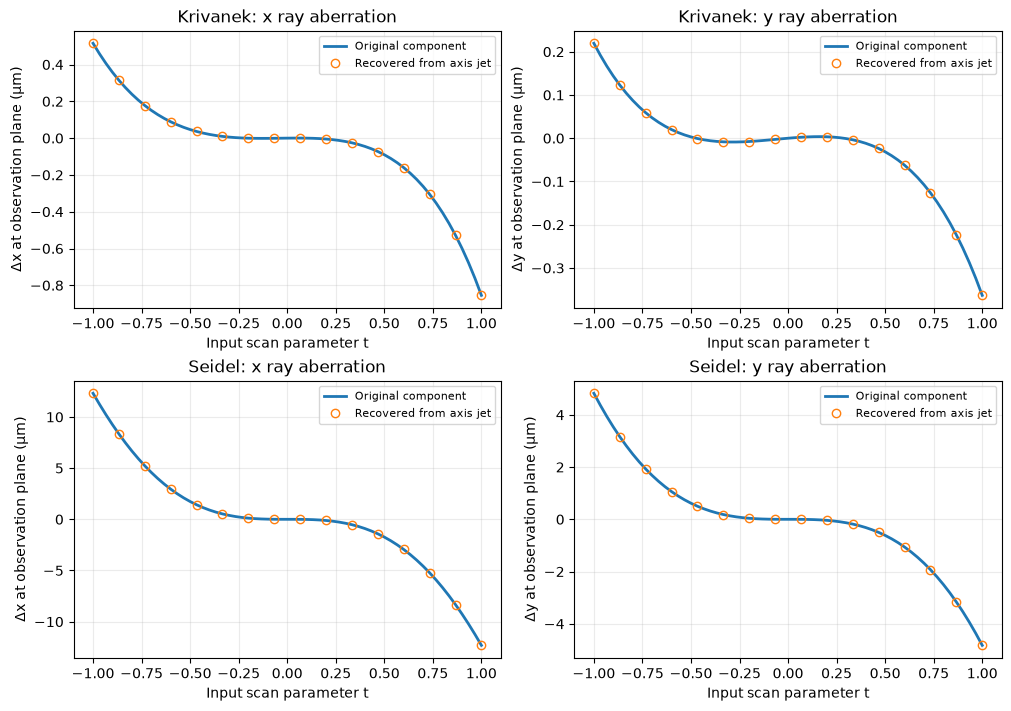

In [7]:
t = np.linspace(-1., 1., 61)
angle = 0.6
k_scan = jnp.asarray(t[:, None] * np.array([0., 0., alpha_scale*np.cos(angle), alpha_scale*np.sin(angle)]))
endpoint_direction = np.array([0.6, -0.35, 0.8, 0.4])
endpoints = length_scale*t[:, None]*endpoint_direction
s_scan = jnp.asarray(np.column_stack((endpoints[:, 2:],
                                      (endpoints[:, 2:]-endpoints[:, :2])/object_distance)))
s_detector = ray_map((seidel_lens, Plane(z=observation_z)))
s_fit_detector = ray_map((seidel_fit_lens, Plane(z=observation_z)))
ideal_detector = ray_map((Lens(z=0., focal_length=focal), Plane(z=observation_z)))
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
for row, (name, original, recovered, inputs) in enumerate([
    ("Krivanek", krivanek_forward, krivanek_fit, k_scan),
    ("Seidel", s_detector, s_fit_detector, s_scan),
]):
    actual = np.asarray(jax.vmap(lambda q: original(q)-ideal_detector(q))(inputs))[:, :2]*1e6
    fitted = np.asarray(jax.vmap(lambda q: recovered(q)-ideal_detector(q))(inputs))[:, :2]*1e6
    for col, coordinate in enumerate(("x", "y")):
        ax = axes[row, col]
        ax.plot(t, actual[:, col], label="Original component", lw=2)
        ax.plot(t[::4], fitted[::4, col], "o", fillstyle="none", label="Recovered from axis jet")
        ax.set(title=f"{name}: {coordinate} ray aberration", xlabel="Input scan parameter t",
               ylabel=f"Δ{coordinate} at observation plane (µm)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
plt.show()

## What this establishes

The recovered numbers come from derivatives **through the native component ray transformations**. Krivanek needs polynomial Cartesian arithmetic to retain high-order axis derivatives. Seidel's polynomial was already regular; what was missing was its singular-ray transformation. That transformation must include both position and slope changes implied by the joint action.

A single on-axis ray value carries none of these higher-order coefficients by itself. Its multivariate jet does. Different tangent seeds resolve that jet without shifting the reference ray.

The Krivanek example includes a downstream drift; the Seidel coefficient conversion is written at the lens exit, where its stationary-action relations apply. For additional separated lenses, differentiate the entire column and interpret the resulting **system** Taylor map in a chosen coordinate basis. These single-lens conversion formulas do not automatically recover each element's coefficients from an arbitrary column.

This is model-based ray aberration extraction with known geometry, not an intensity-only inverse experiment. The Seidel stationary solve assumes a smooth branch near the ideal ray; large aberrations can require a different global branch analysis. Its full ray map has higher-order terms from the implicit position solve, while the third-order on-axis jet still determines the nine quartic coefficients used here.